## Ejercicio 8

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [14]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [15]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [16]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

In [17]:
b7 = A7 @ x_fantoma
rng = np.random.default_rng(67)
z = rng.standard_normal(b7.size)
escala = np.sqrt(np.mean(b7**2))

In [18]:
sigma = 0.06
b_sigma = b7 + sigma * escala * z

### Inciso a)

In [19]:
def costo(x, A, b):
    residuo = A @ x - b
    return 0.5 * np.dot(residuo, residuo)

def gradiente(x, A, b):
    return A.T @ (A @ x - b)

H = A7.T @ A7

print("¿H es simétrica?", np.allclose(H, H.T))  # H es simétrica si y sólo si H = H^T
print("Menor autovalor:", np.linalg.eigvalsh(H)[0]) # El índice 0 apunta al menor autovalor

¿H es simétrica? True
Menor autovalor: 0.5132736028183065


- El costo $E(x)=\frac12\|A_7x-b_\sigma\|^2$ mide qué tan diferentes son las mediciones predichas por una imagen $x$ (dadas por $A_7x$) y las mediciones observadas $b_\sigma$, que contienen ruido. El objetivo de la reconstrucción es encontrar una imagen que minimice esta diferencia.

- El gradiente $\nabla E(x)=A_7^T(A_7x-b_\sigma)$ indica cómo cambia el costo al modificar la imagen $x$.

- La Hessiana $H=A_7^TA_7$ describe la curvatura del costo y no depende de $x$.

- La matriz $H$ es simétrica. Además, para cualquier vector $v$, se cumple que:

  $$
  \begin{aligned}
  v^T H v &= v^T A_7^T A_7 v \\
          &= (A_7 v)^T(A_7 v) \\
          &= \|A_7 v\|^2
  \end{aligned}
  $$

  Reemplazando $H$ por $A_7^TA_7$, obtenemos que  $v^T H v = \|A_7 v\|^2$. 

  Como la norma al cuadrado nunca es negativa ($\|A_7 v\|^2$) , el término $v^T H v$ es siempre $\geq 0$. 
  <br> Como $A_7v\neq 0$ para todo vector $v\neq 0$, entonces $v^THv>0$, y por lo tanto, $H$ es definida positiva para todo vector no nulo. 

  Esto significa que el costo tiene curvatura positiva en todas las direcciones y, al ser una función cuadrática posee un **único** mínimo global.

### Inciso b)

In [20]:
def gradiente_descendiente(A, b, alfa, max_iter=10000, tol=1e-8):
    # Comenzamos con una imagen de ceros y preparamos los historiales
    x = np.zeros(A.shape[1])
    costos = []
    normas_gradiente = []
    iteraciones = 0
    motivo = "máximo de iteraciones"

    for t in range(max_iter + 1):
        # Usamos las funciones del inciso a) para evaluar el costo y el gradiente
        costo_actual = costo(x, A, b)
        grad = gradiente(x, A, b)
        norma_grad = np.linalg.norm(grad)

        # Agregamos el costo y la norma del gradiente
        costos.append(costo_actual)
        normas_gradiente.append(norma_grad)

        # Frenamos si el costo deja de ser finito o si el gradiente ya es lo suficientemente pequeño
        if not np.isfinite(costo_actual):
            motivo = "costo divergente"
            break
        if norma_grad <= tol:
            motivo = "tolerancia del gradiente"
            break
        if t == max_iter:
            break

        # Restamos alfa por el gradiente para obtener la nueva imagen
        x = x - alfa * grad
        iteraciones += 1

    # Guardamos la solución y los datos necesarios para analizar las iteraciones
    resultado = {"x": x, "costos": costos, "normas_gradiente": normas_gradiente,
                 "iteraciones": iteraciones, "motivo": motivo}
    return resultado

Tasa de aprendizaje: 0.027424756403856825
Iteraciones: 1434
Motivo de parada: tolerancia del gradiente
Costo final: 0.09607287885917531
Norma final del gradiente: 9.978479889076394e-11


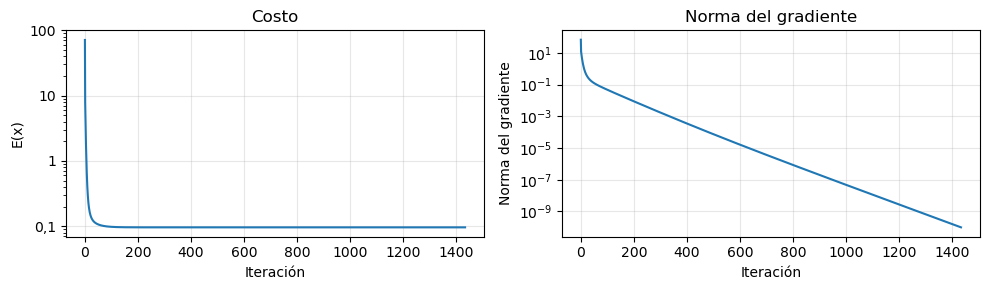

In [21]:
# Elegimos una tasa de aprendizaje a partir del mayor valor propio de H
mu_max = np.linalg.eigvalsh(H)[-1]
alfa = 1.0 / mu_max # Elegimos el inverso del mayor autovalor, ya que permite avanzar de forma estable hacia el mínimo

# Ejecutamos gradiente descendiente para las mediciones ruidosas de este ejercicio
resultado_gd = gradiente_descendiente(A7, b_sigma, alfa, max_iter=10000, tol=1e-10)
x_gd = resultado_gd["x"]

print("Tasa de aprendizaje:", alfa)
print("Iteraciones:", resultado_gd["iteraciones"])
print("Motivo de parada:", resultado_gd["motivo"])
print("Costo final:", resultado_gd["costos"][-1])
print("Norma final del gradiente:", resultado_gd["normas_gradiente"][-1])

# Mostramos cómo evolucionan el costo y la norma del gradiente.
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].semilogy(resultado_gd["costos"])
axs[0].set_title("Costo")
axs[0].set_ylabel("E(x)")

# Mostramos los valores del costo en formato decimal.
axs[0].set_yticks([0.1, 1, 10, 100])
axs[0].set_yticklabels(["0,1", "1", "10", "100"])

axs[1].semilogy(resultado_gd["normas_gradiente"])
axs[1].set_title("Norma del gradiente")
axs[1].set_ylabel("Norma del gradiente")

for ax in axs:
    ax.set_xlabel("Iteración")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Inciso c)

Mayor valor propio de H: 36.46340500801557
Intervalo estable: 0 < alfa < 0.05484951280771365

Factor: 0.2 , Tasa de aprendizaje: 0.005484951280771365
(La tasa está dentro del intervalo estable)
Costo inicial: 71.16972605184317 / Costo final: 0.11241537607448987
Iteraciones: 200

Factor: 1.0 , Tasa de aprendizaje: 0.027424756403856825
(La tasa está dentro del intervalo estable)
Costo inicial: 71.16972605184317 / Costo final: 0.09613709975849248
Iteraciones: 200

Factor: 1.8 , Tasa de aprendizaje: 0.04936456152694228
(La tasa está dentro del intervalo estable)
Costo inicial: 71.16972605184317 / Costo final: 0.09607323122143048
Iteraciones: 200

Factor: 2.2 , Tasa de aprendizaje: 0.060334464088485015
(La tasa está fuera del intervalo estable)
Costo inicial: 71.16972605184317 / Costo final: 2.6671972565306997e+33
Iteraciones: 200



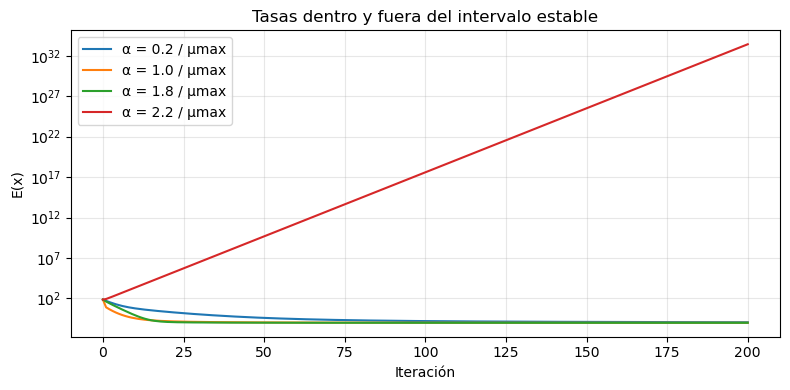

In [22]:
# Calculamos el mayor valor propio de H y el límite para una tasa estable
valores_propios = np.linalg.eigvalsh(H)
mu_max = valores_propios[-1]
limite_alfa = 2 / mu_max

print("Mayor valor propio de H:", mu_max)
print("Intervalo estable: 0 < alfa <", limite_alfa)
print()

# Probamos tres tasas dentro del intervalo y una fuera
factores = [0.2, 1.0, 1.8, 2.2]
fig, ax = plt.subplots(figsize=(8, 4))

for factor in factores:
    tasa = factor / mu_max

    # Cada llamada empieza con una imagen de ceros y permite hasta 200 iteraciones
    resultado = gradiente_descendiente(A7, b_sigma, tasa, max_iter=200, tol=1e-10)
    costos_prueba = resultado["costos"]

    # Comparamos el costo inicial y final para ver cómo se comporta cada tasa
    print("Factor:", factor, ", Tasa de aprendizaje:", tasa)
    if 0 < tasa < limite_alfa:
        print("(La tasa está dentro del intervalo estable)")
    else:
        print("(La tasa está fuera del intervalo estable)")
    print("Costo inicial:", costos_prueba[0], "/ Costo final:", costos_prueba[-1])
    print("Iteraciones:", resultado["iteraciones"])
    print()

    # La escala logarítmica permite mostrar el descenso y el crecimiento del costo
    etiqueta = "α = " + str(factor) + " / μmax"
    ax.semilogy(costos_prueba, label=etiqueta)

ax.set_xlabel("Iteración")
ax.set_ylabel("E(x)")
ax.set_title("Tasas dentro y fuera del intervalo estable")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Con los factores $0.2, 1.0$ y $1.8$, el costo disminuye y tiende a estabilizarse. Estas tasas están dentro del intervalo estable y el método se acerca a la solución. Con el factor $0.2$ el descenso es más lento; con $1.0$ y $1.8$ se alcanzan costos menores en las 200 iteraciones probadas.

Con el factor $2.2$, que está fuera del intervalo estable, el costo crece cada vez más en vez de estabilizarse. En este caso el método se vuelve inestable y diverge.

### Inciso d)

In [23]:
# Partimos de una imagen con todos sus píxeles en cero
x0 = np.zeros(n**2)

# Calculamos el gradiente inicial y resolvemos H @ p0 
gradiente_inicial = gradiente(x0, A7, b_sigma)
p0 = np.linalg.solve(H, gradiente_inicial)

# Aplicamos una sola actualización del método de Newton
x_newton = x0 - p0

# Comprobamos si el gradiente quedó cerca de cero
gradiente_final = gradiente(x_newton, A7, b_sigma)
norma_gradiente_final = np.linalg.norm(gradiente_final)

print("(Después de una iteración de Newton)")
print("Norma del gradiente:", norma_gradiente_final)

(Después de una iteración de Newton)
Norma del gradiente: 1.733347233624306e-14


Después de una sola iteración de Newton, la norma del gradiente es aproximadamente $1{,}73 \times 10^{-14}$, es decir prácticamente cero. Esto verifica que se alcanzó el mínimo.

Esto ocurre porque, para una función cuadrática con Hessiana constante, la aproximación que utiliza Newton coincide exactamente con la función. Por eso, el paso calculado lleva directamente al mínimo en una sola iteración.

### Inciso e)

Gradiente descendiente
Costo: 0.09607287885917531
Norma del gradiente: 9.978479889076394e-11
Error relativo: 0.1289649075713366

Newton
Costo: 0.09607287885917523
Norma del gradiente: 1.733347233624306e-14
Error relativo: 0.12896490758567403

lstsq
Costo: 0.09607287885917526
Norma del gradiente: 6.212536955172913e-14
Error relativo: 0.12896490758567475



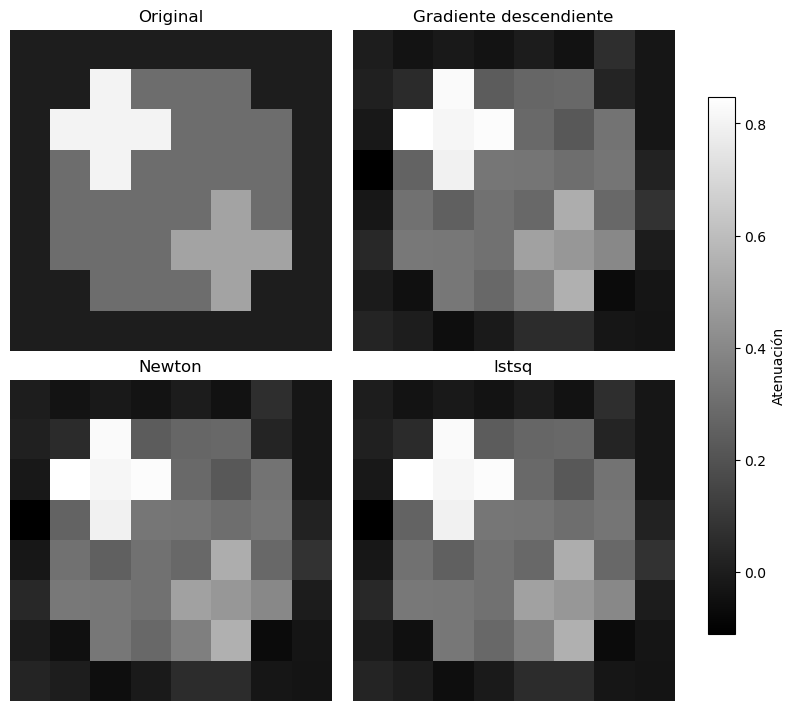

In [24]:
# Calculamos la solución de mínimos cuadrados para compararla con los otros métodos
x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
nombres = ["Gradiente descendiente", "Newton", "lstsq"]
soluciones = [x_gd, x_newton, x_lstsq]

# Para cada método mostramos el costo, la norma del gradiente y el error respecto del fantoma
for i in range(3):
    x = soluciones[i]
    error = np.linalg.norm(x - x_fantoma) / np.linalg.norm(x_fantoma)
    distancia = np.linalg.norm(x - x_lstsq)

    print(nombres[i])
    print("Costo:", costo(x, A7, b_sigma))
    print("Norma del gradiente:", np.linalg.norm(gradiente(x, A7, b_sigma)))
    print("Error relativo:", error)
    print()

# Preparamos las cuatro imágenes y usamos la misma escala de grises para compararlas
imagenes = [X_fantoma, x_gd.reshape(n, n), x_newton.reshape(n, n), x_lstsq.reshape(n, n)]
titulos = ["Original", "Gradiente descendiente", "Newton", "lstsq"]
vmin = np.min(imagenes)
vmax = np.max(imagenes)

# Mostramos dos imágenes por fila y agregamos una barra de color común
fig, axs = plt.subplots(2, 2, figsize=(8, 7), layout="constrained")
k = 0
for fila in range(2):
    for columna in range(2):
        axs[fila, columna].imshow(imagenes[k], cmap="gray", vmin=vmin, vmax=vmax)
        axs[fila, columna].set_title(titulos[k])
        axs[fila, columna].axis("off")
        k += 1

fig.colorbar(axs[0, 0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()


Los tres métodos llegan a reconstrucciones prácticamente iguales, dentro de las tolerancias definidas. Sin embargo, el error respecto del fantoma sigue siendo de aproximadamente $0,129$, debido al ruido que tienen las mediciones. 
<br> Esto pasa porque los métodos no eliminan el ruido, sino que buscan la mejor solución posible teniendo en cuenta las mediciones con ruido.

La diferencia entre ellos está en cómo llegan a esa solución: El **descenso por gradiente** necesita una tasa de aprendizaje y varias iteraciones para acercarse al mínimo. El **método de Newton** llega al mínimo en una sola iteración usando la Hessiana. 
<br> Por último, **lstsq** calcula directamente la solución de mínimos cuadrados sin necesidad de elegir una tasa de aprendizaje.

En **conclusión**, los tres métodos obtienen resultados similares, pero se diferencian en la forma de calcular la solución y eso también impacta en el costo computacional.